In [8]:
import marimo as mo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Solar Power Data Exploration

Exploratory analysis of the SOLETE Pombo hourly dataset: structural inspection, temporal validation, and target audit.

## Data Loading

The dataset is `SOLETE_Pombo_60min_v4.parquet`, recorded hourly at the DTU Risø campus, Denmark. Timestamps are in UTC.

The hourly SOLETE Pombo dataset is loaded from the Parquet file. No filtering or transformation is applied during loading.

In [39]:
from daybreak_gp.paths import SOLETE_PARQUET

df = pd.read_parquet(SOLETE_PARQUET)

## Structural Inspection

Review dataset dimensions, schema, data types, and missing-value counts before any temporal or target-specific analysis.

In [10]:
df.shape

(10969, 37)

In [11]:
df.head()

,timestamp,TEMPERATURE[degC],HUMIDITY[%],WIND_SPEED[m1s],WIND_DIR[deg],GHI[kW1m2],POA Irr[kW1m2],P_Gaia[kW],P_Solar[kW],Pressure[mbar],...,P_Gaia[kW]_qc_frac_flagged,Pac,Pdc,TempModule,TempCell,P_Solar[kW]_qc,P_Solar_clean[kW],P_hybrid[kW],P_hybrid[kW]_qc,P_hybrid[kW]_qc_source
0,2018-06-01 00:00:00+00:00,14.161222,0.700000,1.306389,109.864970,0.000000,0.000000,0.0,0.000000,NaN,...,1.0,0.000000,0.000000,14.161222,14.161222,0,0.000000,0.000000,7,2
1,2018-06-01 01:00:00+00:00,13.392278,0.700000,1.018417,74.655825,0.000000,0.000000,0.0,0.000000,NaN,...,1.0,0.000000,0.000000,13.392278,13.392278,0,0.000000,0.000000,7,2
2,2018-06-01 02:00:00+00:00,13.047472,0.701278,1.094333,91.235599,0.002930,0.003503,0.0,0.026991,NaN,...,1.0,0.026999,0.027522,13.139245,13.149754,0,0.026991,0.026991,7,2
3,2018-06-01 03:00:00+00:00,13.105583,0.731361,0.750222,58.340126,0.035402,0.021412,0.0,0.164431,NaN,...,1.0,0.164586,0.167774,13.681197,13.745433,0,0.164431,0.164431,7,2
4,2018-06-01 04:00:00+00:00,14.680333,0.700000,1.069194,77.664747,0.117444,0.050737,0.0,0.385595,NaN,...,1.0,0.385764,0.393235,16.012037,16.164247,0,0.385595,0.385595,7,2


In [12]:
df.tail()

,timestamp,TEMPERATURE[degC],HUMIDITY[%],WIND_SPEED[m1s],WIND_DIR[deg],GHI[kW1m2],POA Irr[kW1m2],P_Gaia[kW],P_Solar[kW],Pressure[mbar],...,P_Gaia[kW]_qc_frac_flagged,Pac,Pdc,TempModule,TempCell,P_Solar[kW]_qc,P_Solar_clean[kW],P_hybrid[kW],P_hybrid[kW]_qc,P_hybrid[kW]_qc_source
10964,2019-08-31 20:00:00+00:00,21.335389,0.889889,3.722111,130.726871,0.0,0.0,0.0,0.0,NaN,...,1.0,0.0,0.0,21.335389,21.335389,0,0.0,0.0,7,2
10965,2019-08-31 21:00:00+00:00,21.059806,0.799056,4.059889,146.813428,0.0,0.0,0.0,0.0,NaN,...,1.0,0.0,0.0,21.059806,21.059806,0,0.0,0.0,7,2
10966,2019-08-31 22:00:00+00:00,21.504611,0.793528,3.859694,134.462791,0.0,0.0,0.0,0.0,NaN,...,1.0,0.0,0.0,21.504611,21.504611,0,0.0,0.0,7,2
10967,2019-08-31 23:00:00+00:00,20.802500,0.799444,1.578861,129.277279,0.0,0.0,0.0,0.0,NaN,...,1.0,0.0,0.0,20.802500,20.802500,0,0.0,0.0,7,2
10968,2019-09-01 00:00:00+00:00,0.000000,0.800000,1.600000,0.000000,0.0,0.0,0.0,0.0,NaN,...,1.0,0.0,0.0,0.000000,0.000000,0,0.0,0.0,7,2


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10969 entries, 0 to 10968
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype              
---  ------                             --------------  -----              
 0   timestamp                          10969 non-null  datetime64[ns, UTC]
 1   TEMPERATURE[degC]                  10969 non-null  float64            
 2   HUMIDITY[%]                        10945 non-null  float64            
 3   WIND_SPEED[m1s]                    10969 non-null  float64            
 4   WIND_DIR[deg]                      10969 non-null  float64            
 5   GHI[kW1m2]                         10969 non-null  float64            
 6   POA Irr[kW1m2]                     10969 non-null  float64            
 7   P_Gaia[kW]                         10969 non-null  float64            
 8   P_Solar[kW]                        10969 non-null  float64            
 9   Pressure[mbar]                     13 non-null     float64   

In [14]:
df.columns.tolist()

['timestamp',
 'TEMPERATURE[degC]',
 'HUMIDITY[%]',
 'WIND_SPEED[m1s]',
 'WIND_DIR[deg]',
 'GHI[kW1m2]',
 'POA Irr[kW1m2]',
 'P_Gaia[kW]',
 'P_Solar[kW]',
 'Pressure[mbar]',
 'Azimuth[deg]',
 'Elevation[deg]',
 'WIND_DIR[deg]_qc_worst',
 'Pressure[mbar]_qc_worst',
 'WIND_SPEED[m1s]_qc_worst',
 'HUMIDITY[%]_qc_worst',
 'TEMPERATURE[degC]_qc_worst',
 'GHI[kW1m2]_qc_worst',
 'POA Irr[kW1m2]_qc_worst',
 'P_Gaia[kW]_qc_worst',
 'WIND_DIR[deg]_qc_frac_flagged',
 'Pressure[mbar]_qc_frac_flagged',
 'WIND_SPEED[m1s]_qc_frac_flagged',
 'HUMIDITY[%]_qc_frac_flagged',
 'TEMPERATURE[degC]_qc_frac_flagged',
 'GHI[kW1m2]_qc_frac_flagged',
 'POA Irr[kW1m2]_qc_frac_flagged',
 'P_Gaia[kW]_qc_frac_flagged',
 'Pac',
 'Pdc',
 'TempModule',
 'TempCell',
 'P_Solar[kW]_qc',
 'P_Solar_clean[kW]',
 'P_hybrid[kW]',
 'P_hybrid[kW]_qc',
 'P_hybrid[kW]_qc_source']

In [15]:
df.isnull().sum()

timestamp                                0
TEMPERATURE[degC]                        0
HUMIDITY[%]                             24
WIND_SPEED[m1s]                          0
WIND_DIR[deg]                            0
GHI[kW1m2]                               0
POA Irr[kW1m2]                           0
P_Gaia[kW]                               0
P_Solar[kW]                              0
Pressure[mbar]                       10956
Azimuth[deg]                             0
Elevation[deg]                           0
WIND_DIR[deg]_qc_worst                   0
Pressure[mbar]_qc_worst                  0
WIND_SPEED[m1s]_qc_worst                 0
HUMIDITY[%]_qc_worst                     0
TEMPERATURE[degC]_qc_worst               0
GHI[kW1m2]_qc_worst                      0
POA Irr[kW1m2]_qc_worst                  0
P_Gaia[kW]_qc_worst                      0
WIND_DIR[deg]_qc_frac_flagged            0
Pressure[mbar]_qc_frac_flagged           0
WIND_SPEED[m1s]_qc_frac_flagged          0
HUMIDITY[%]

### Structural Observations

- 10,969 hourly records with a timestamp column and candidate solar power columns.
- Raw and cleaned solar targets contain no missing values.

### Key Columns

| Column | What it represents |
|---|---|
| `P_Solar[kW]` | Actual measured solar power |
| `P_Solar_clean[kW]` | Solar power after the dataset's cleaning process |
| `Pac` | Solar power estimated by a physical PV model |
| `P_Solar[kW]_qc` | Flag indicating whether a measurement was replaced by the model |
| `Elevation[deg]` | Sun's elevation above or below the horizon, calculated using timestamp and location |

`P_Solar[kW]` contains measured values. `Pac` and any model-based replacements in `P_Solar_clean[kW]` are model-generated.

### Missing Values

- `HUMIDITY[%]`: 24 missing values.
- `Pressure[mbar]`: 10,956 missing values.

Humidity values are stored between 0 and 1, despite `%` appearing in the column name. The missing values are associated with a faulty sensor on 2018-11-17.

Pressure readings are valid only on 2019-01-16. Other readings were placeholders and were replaced with missing values.

## Temporal Validation

Verify timestamp uniqueness, chronological ordering, sampling cadence, and continuity of the hourly series.

In [16]:
df["timestamp"].duplicated().sum()

np.int64(0)

In [17]:
time_diffs = df["timestamp"].diff()
time_diffs.value_counts()

timestamp
0 days 01:00:00    10968
Name: count, dtype: int64

### Temporal Coverage and Continuity

- Start: 2018-06-01 00:00 UTC
- End: 2019-09-01 00:00 UTC
- Total rows: 10,969
- Complete hourly observations: 10,968
- Final partial observation: 2019-09-01 00:00:00 UTC, containing only one second
- Sampling frequency: Hourly
- Duplicate timestamps: None
- Chronological ordering: Confirmed
- Timestamps are unique and have one-hour differences.

The final row is not a complete hourly observation and must be excluded from modelling and window selection.

## Target Audit

Compare the raw and cleaned solar power series, quantify their differences, and audit nighttime values and QC flags before selecting a prediction target.

### Candidate Targets

Identify the candidate solar power columns and compare their distributions.

In [18]:
df.columns.tolist()

['timestamp',
 'TEMPERATURE[degC]',
 'HUMIDITY[%]',
 'WIND_SPEED[m1s]',
 'WIND_DIR[deg]',
 'GHI[kW1m2]',
 'POA Irr[kW1m2]',
 'P_Gaia[kW]',
 'P_Solar[kW]',
 'Pressure[mbar]',
 'Azimuth[deg]',
 'Elevation[deg]',
 'WIND_DIR[deg]_qc_worst',
 'Pressure[mbar]_qc_worst',
 'WIND_SPEED[m1s]_qc_worst',
 'HUMIDITY[%]_qc_worst',
 'TEMPERATURE[degC]_qc_worst',
 'GHI[kW1m2]_qc_worst',
 'POA Irr[kW1m2]_qc_worst',
 'P_Gaia[kW]_qc_worst',
 'WIND_DIR[deg]_qc_frac_flagged',
 'Pressure[mbar]_qc_frac_flagged',
 'WIND_SPEED[m1s]_qc_frac_flagged',
 'HUMIDITY[%]_qc_frac_flagged',
 'TEMPERATURE[degC]_qc_frac_flagged',
 'GHI[kW1m2]_qc_frac_flagged',
 'POA Irr[kW1m2]_qc_frac_flagged',
 'P_Gaia[kW]_qc_frac_flagged',
 'Pac',
 'Pdc',
 'TempModule',
 'TempCell',
 'P_Solar[kW]_qc',
 'P_Solar_clean[kW]',
 'P_hybrid[kW]',
 'P_hybrid[kW]_qc',
 'P_hybrid[kW]_qc_source']

In [19]:
df[["P_Solar[kW]", "P_Solar_clean[kW]"]].describe()

,P_Solar[kW],P_Solar_clean[kW]
count,10969.000000,10969.000000
mean,1.024377,1.024361
std,1.649652,1.649662
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.077609,0.077609
75%,1.393246,1.393246
max,6.969382,6.969382


In [20]:
target = df[["P_Solar[kW]", "P_Solar_clean[kW]"]]

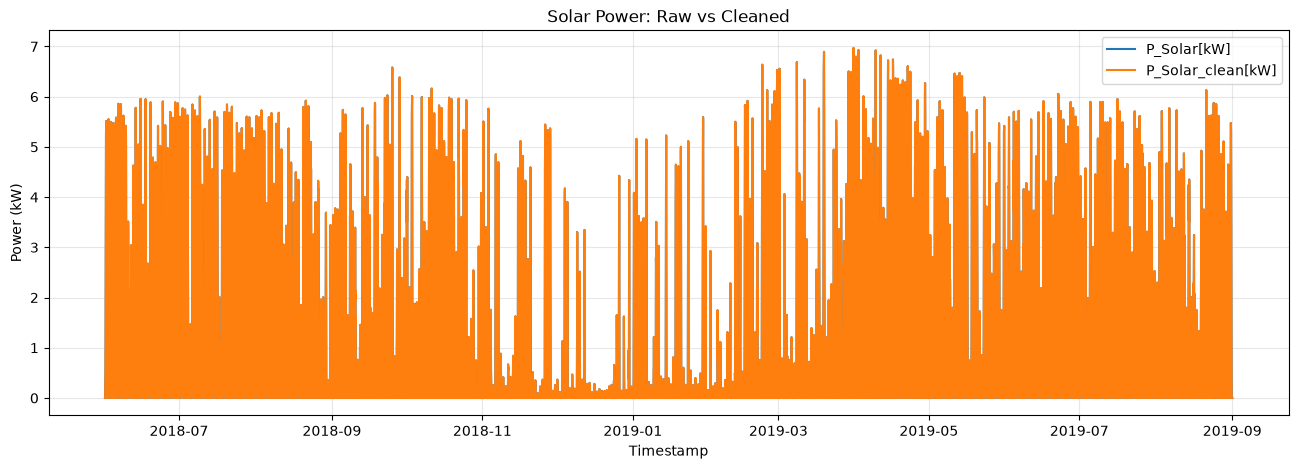

In [21]:
plt.figure(figsize=(16, 5))
plt.plot(df["timestamp"], target)

plt.xlabel("Timestamp")
plt.ylabel("Power (kW)")
plt.title("Solar Power: Raw vs Cleaned")
plt.legend(target.columns)
plt.grid(alpha=0.3)

plt.show()

### Raw vs. Cleaned Series

`P_Solar[kW]` contains measured solar power and is never overwritten. `P_Solar_clean[kW]` starts with measured power. It replaces measured power with the physical model's estimate (`Pac`) when the substitution condition is met. It also sets values less than or equal to 0.001 kW to zero. A `P_Solar[kW]_qc` value of 6 identifies measurements replaced by the physical model.

The analysis below compares the two series and inspects the largest absolute differences.

The audit found:

- 739 observations where raw and cleaned power differ.
- All 739 differences have raw power greater than cleaned power.
- The maximum difference is approximately 0.000997 kW.
- The sum of `P_Solar[kW]_qc` is zero.

There are zero model-replaced observations in this hourly dataset. The 739 differences are explained by the cleaning process setting very small readings to zero, not by model replacement.

Project target decision:

- Primary target: `P_Solar[kW]`, because we want to investigate whether non-stationary GPs model the actual measured solar generation signal better.
- Sensitivity target: `P_Solar_clean[kW]`, to check whether the cleaning threshold changes our results.

This is an experimental design decision based on data provenance, not a conclusion established by this EDA.

In [22]:
diff = df["P_Solar[kW]"] - df["P_Solar_clean[kW]"]

In [23]:
print((diff!=0).sum())

739


In [24]:
diff.describe()

count    10969.000000
mean         0.000016
std          0.000093
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.000997
dtype: float64

In [25]:
diff.abs().mean()

np.float64(1.5787674959072482e-05)

In [26]:
diff.abs().max()

np.float64(0.0009969625038071025)

In [27]:
df.loc[diff.nlargest(10).index, 
       ["timestamp", "P_Solar[kW]", "P_Solar_clean[kW]", "Elevation[deg]"]]

,timestamp,P_Solar[kW],P_Solar_clean[kW],Elevation[deg]
6857,2019-03-13 17:00:00+00:00,0.000997,0.0,-3.512307
10891,2019-08-28 19:00:00+00:00,0.000993,0.0,-10.058415
1197,2018-07-20 21:00:00+00:00,0.000992,0.0,-10.330141
44,2018-06-02 20:00:00+00:00,0.000990,0.0,-4.947483
6208,2019-02-14 16:00:00+00:00,0.000985,0.0,-2.945250
6665,2019-03-05 17:00:00+00:00,0.000985,0.0,-5.900415
7774,2019-04-20 22:00:00+00:00,0.000983,0.0,-22.023257
7848,2019-04-24 00:00:00+00:00,0.000979,0.0,-19.492420
4049,2018-11-16 17:00:00+00:00,0.000970,0.0,-20.169645
5306,2019-01-08 02:00:00+00:00,0.000969,0.0,-41.445559


### Nighttime Generation

`Elevation[deg]` is calculated using the timestamp and location. Hourly elevation is the average elevation over the hour, so `Elevation[deg] < 0` means the average solar elevation for that hour was below the horizon. It does not necessarily mean the sun was below the horizon during every second of that hour.

The checks below inspect non-zero solar power readings during negative average elevation. These readings are not automatically errors, and their validity has not been established.

In [28]:
night_mask = df["Elevation[deg]"]  < 0
night_df = df[night_mask]

In [29]:
((night_df["P_Solar[kW]"] != 0).sum() / len(night_df)) * 100

np.float64(31.426875123688898)

In [30]:
night_nonzero = night_df.loc[
    night_df["P_Solar[kW]"] != 0,
    "P_Solar[kW]"
]

night_nonzero.describe()

count    1588.000000
mean        0.007127
std         0.016189
min         0.000002
25%         0.000130
50%         0.001238
75%         0.005874
max         0.277321
Name: P_Solar[kW], dtype: float64

In [31]:
df.loc[
    night_nonzero.nlargest(10).index,
    ["timestamp", "P_Solar[kW]", "Elevation[deg]"]
]

,timestamp,P_Solar[kW],Elevation[deg]
3735,2018-11-03 15:00:00+00:00,0.277321,-0.920321
6424,2019-02-23 16:00:00+00:00,0.199646,-0.294673
6400,2019-02-22 16:00:00+00:00,0.122882,-0.590353
6342,2019-02-20 06:00:00+00:00,0.120844,-0.037760
4543,2018-12-07 07:00:00+00:00,0.117705,-0.176526
5599,2019-01-20 07:00:00+00:00,0.116014,-0.131207
6232,2019-02-15 16:00:00+00:00,0.115184,-2.651791
5575,2019-01-19 07:00:00+00:00,0.108756,-0.288349
5551,2019-01-18 07:00:00+00:00,0.091018,-0.438451
5559,2019-01-18 15:00:00+00:00,0.084175,-2.294537


In [32]:
df.loc[
    night_nonzero.nlargest(10).index,
    ["timestamp", "P_Solar[kW]", "P_Solar_clean[kW]",
     "P_Solar[kW]_qc"]
]

,timestamp,P_Solar[kW],P_Solar_clean[kW],P_Solar[kW]_qc
3735,2018-11-03 15:00:00+00:00,0.277321,0.277321,0
6424,2019-02-23 16:00:00+00:00,0.199646,0.199646,0
6400,2019-02-22 16:00:00+00:00,0.122882,0.122882,0
6342,2019-02-20 06:00:00+00:00,0.120844,0.120844,0
4543,2018-12-07 07:00:00+00:00,0.117705,0.117705,0
5599,2019-01-20 07:00:00+00:00,0.116014,0.116014,0
6232,2019-02-15 16:00:00+00:00,0.115184,0.115184,0
5575,2019-01-19 07:00:00+00:00,0.108756,0.108756,0
5551,2019-01-18 07:00:00+00:00,0.091018,0.091018,0
5559,2019-01-18 15:00:00+00:00,0.084175,0.084175,0


### QC Flags and Missingness

Check whether the QC column identifies modified observations and confirm target zero/missingness counts.

In [33]:
df["P_Solar[kW]_qc"].sum()

np.int64(0)

In [34]:
df[["P_Solar[kW]", "P_Solar_clean[kW]"]].describe()

,P_Solar[kW],P_Solar_clean[kW]
count,10969.000000,10969.000000
mean,1.024377,1.024361
std,1.649652,1.649662
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.077609,0.077609
75%,1.393246,1.393246
max,6.969382,6.969382


In [35]:
df[["P_Solar[kW]", "P_Solar_clean[kW]"]].isna().sum()

P_Solar[kW]          0
P_Solar_clean[kW]    0
dtype: int64

In [36]:
(df[["P_Solar[kW]", "P_Solar_clean[kW]"]] == 0).sum()

P_Solar[kW]          3468
P_Solar_clean[kW]    4207
dtype: int64

In [37]:
(df["P_Solar[kW]"] != df["P_Solar_clean[kW]"]).sum()

np.int64(739)

In [38]:
df[(df["P_Solar[kW]"] != df["P_Solar_clean[kW]"]) & (df["P_Solar_clean[kW]"] == 0)].shape

(739, 37)

## Target Audit Findings

### Dataset overview

The dataset contains 10,969 rows spanning 1 June 2018 to 1 September 2019. Of these, 10,968 are complete hourly observations; the final row at `2019-09-01 00:00:00 UTC` is a partial observation containing only one second.

| Property | Result |
|---|---:|
| Total rows | 10,969 |
| Complete hourly observations | 10,968 |
| Final partial observation | 2019-09-01 00:00:00 UTC (one second) |
| Missing timestamps | 0 |
| Duplicate timestamps | 0 |
| Missing hourly intervals | 0 |
| Missing values in `P_Solar[kW]` | 0 |
| Missing values in `P_Solar_clean[kW]` | 0 |

### Raw vs. cleaned target

The two candidate target columns were compared:

- `P_Solar[kW]`: Measured solar power.
- `P_Solar_clean[kW]`: Solar power after the dataset's cleaning process.

| Statistic | Raw | Cleaned |
|---|---:|---:|
| Mean (kW) | 1.024377 | 1.024361 |
| Standard deviation (kW) | 1.649652 | 1.649662 |
| Minimum (kW) | 0.000000 | 0.000000 |
| Median (kW) | 0.077609 | 0.077609 |
| Maximum (kW) | 6.969382 | 6.969382 |
| Zero-valued observations | 3,468 | 4,207 |

### Differences between the two series

- 739 observations have different raw and cleaned values.
- The mean absolute difference across all observations is approximately `0.00001579 kW`.
- The maximum absolute difference is approximately `0.000997 kW`.
- All 739 differences are in the direction of raw power being greater than cleaned power.
- All 739 differing observations have a cleaned value of exactly zero, verified using a compound Boolean condition.

The cleaned series sets 739 small positive readings to zero. These are not model replacements.

### QC observations

The column `P_Solar[kW]_qc` contains zero for all 10,969 observations, so its sum is zero. A value of `6` would identify a measurement replaced by the physical model, but no such values occur in this hourly dataset.

### Target decision

This is an experimental design decision based on data provenance, not a result established by this EDA.

- Primary target: `P_Solar[kW]`, because we want to investigate whether non-stationary GPs model the actual measured solar generation signal better.
- Sensitivity target: `P_Solar_clean[kW]`, to check whether the cleaning threshold changes our results.

The dataset audit supports this choice:

- No measurements were replaced by the physical model in this hourly dataset.
- The 739 changed values are due to the zeroing threshold, not model replacement.
- The final partial hourly observation at `2019-09-01 00:00:00 UTC` must be excluded from modelling and window selection.